# 1. Linear growth

**Model:** $y(t) = a + b\,t$

- $a$ is the starting value (the value at $t = 0$).
- $b$ is the constant rate of change (the slope). Equal time steps give equal **additions**.
- Signature: the first differences $\Delta y$ are constant.

**Why it matters in Grade 11.** Linear growth is the baseline that exponential growth is usually contrasted with. The intuition that "growth is linear" is also what the exponential growth bias literature describes (for example Timmers & Wagenaar, 1977; Schonger & Sele, 2021).

All data in this notebook is **simulated**, so the true parameters are known and we can check how well the fits recover them.

**Contents**
1. The model and its parameters
2. The constant-difference signature
3. Simulated example A: weekly savings (fit, residuals, prediction)
4. Simulated example B: a draining tank (negative slope)
5. A simulation of the simulation: how much do estimates vary between experiments?
6. Using your own data
7. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
rng = np.random.default_rng(2026)   # fixed seed: results are reproducible

## 1. The model and its parameters

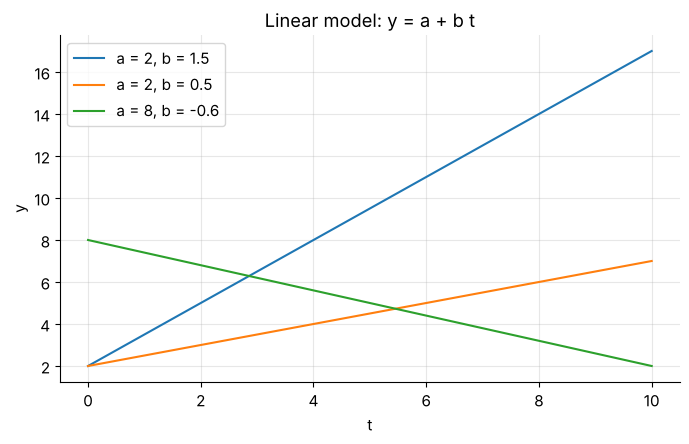

In [2]:
def linear(t, a, b):
    return a + b * t

t = np.linspace(0, 10, 200)
fig, ax = plt.subplots()
for a, b in [(2, 1.5), (2, 0.5), (8, -0.6)]:
    ax.plot(t, linear(t, a, b), label=f"a = {a}, b = {b}")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title("Linear model: y = a + b t")
ax.legend()
plt.show()

## 2. The signature: constant differences

For a linear model every step of the same size adds the same amount. The **relative** growth $\Delta y / y$ is *not* constant: it shrinks as $y$ grows. Compare this with the exponential notebook, where the ratio is constant instead.

In [3]:
t_int = np.arange(0, 8)
y_int = linear(t_int, 5, 3)
print("t      :", t_int)
print("y      :", y_int)
print("Δy     :", np.diff(y_int), " <- constant first differences")
print("Δy / y :", np.round(np.diff(y_int) / y_int[:-1], 3), " <- relative growth is NOT constant")

t      : [0 1 2 3 4 5 6 7]
y      : [ 5  8 11 14 17 20 23 26]
Δy     : [3 3 3 3 3 3 3]  <- constant first differences
Δy / y : [0.6   0.375 0.273 0.214 0.176 0.15  0.13 ]  <- relative growth is NOT constant


## 3. Simulated example A: weekly savings

A student starts with €20 and saves €7.50 per week. Small irregular extra spending adds noise (standard deviation €6). We pretend we only see the noisy balances and try to recover $a$ and $b$.

In [4]:
true_a, true_b, sigma = 20.0, 7.5, 6.0
weeks = np.arange(0, 21)
savings = linear(weeks, true_a, true_b) + rng.normal(0, sigma, size=weeks.size)

fit = stats.linregress(weeks, savings)
n = weeks.size
tcrit = stats.t.ppf(0.975, df=n - 2)

print(f"Estimated intercept a = {fit.intercept:6.2f}   (true {true_a})")
print(f"Estimated slope     b = {fit.slope:6.2f}   (true {true_b})")
print(f"95% interval for b    : {fit.slope - tcrit * fit.stderr:.2f} to {fit.slope + tcrit * fit.stderr:.2f}")
print(f"R² = {fit.rvalue ** 2:.4f}")

Estimated intercept a =  20.03   (true 20.0)
Estimated slope     b =   7.43   (true 7.5)
95% interval for b    : 7.09 to 7.76
R² = 0.9912


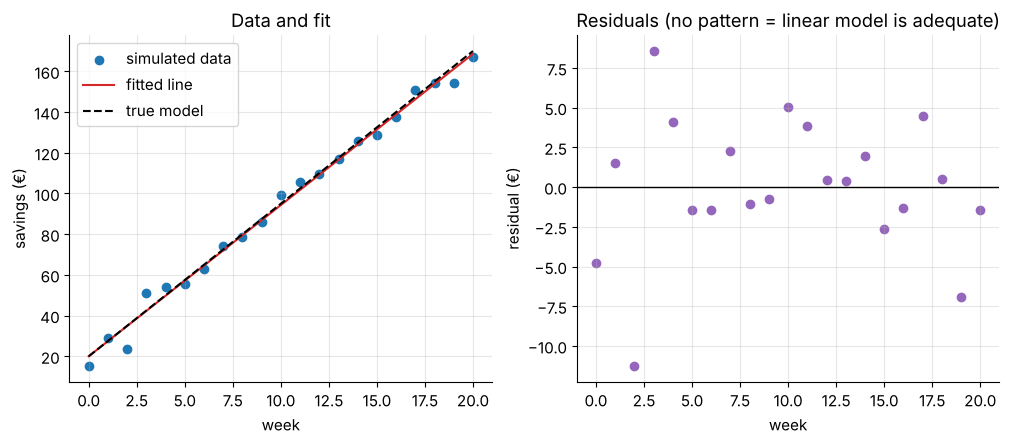

In [5]:
fitted = linear(weeks, fit.intercept, fit.slope)
residuals = savings - fitted

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(weeks, savings, label="simulated data", color="tab:blue")
axes[0].plot(weeks, fitted, color="tab:red", label="fitted line")
axes[0].plot(weeks, linear(weeks, true_a, true_b), "k--", label="true model")
axes[0].set_xlabel("week")
axes[0].set_ylabel("savings (€)")
axes[0].set_title("Data and fit")
axes[0].legend()

axes[1].axhline(0, color="k", lw=1)
axes[1].scatter(weeks, residuals, color="tab:purple")
axes[1].set_xlabel("week")
axes[1].set_ylabel("residual (€)")
axes[1].set_title("Residuals (no pattern = linear model is adequate)")
plt.show()

In [6]:
target = 250
week_hit = (target - fit.intercept) / fit.slope
print(f"Predicted week at which savings reach €{target}: {week_hit:.1f}")
print(f"True model gives                            : {(target - true_a) / true_b:.1f}")

Predicted week at which savings reach €250: 31.0
True model gives                            : 30.7


## 4. Simulated example B: a draining tank (negative slope)

A tank starts at 120 cm and the level falls 3.2 cm per hour. Measurements have an error of 1.5 cm. Here $b<0$: the same model describes linear *decrease*.

Estimated slope: -3.16 cm/h (true -3.2)
Predicted time to empty: 38.1 h (true 37.5 h)


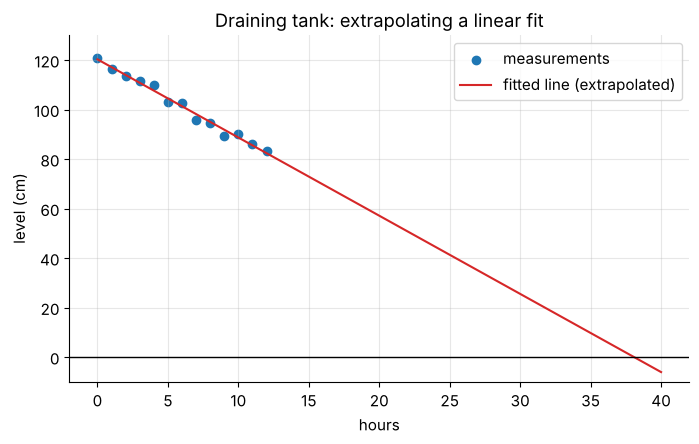

In [7]:
tank_a, tank_b, tank_sigma = 120.0, -3.2, 1.5
hours = np.arange(0, 13)
level = linear(hours, tank_a, tank_b) + rng.normal(0, tank_sigma, hours.size)

fit_tank = stats.linregress(hours, level)
t_empty = -fit_tank.intercept / fit_tank.slope

print(f"Estimated slope: {fit_tank.slope:.2f} cm/h (true {tank_b})")
print(f"Predicted time to empty: {t_empty:.1f} h (true {-tank_a / tank_b:.1f} h)")

fig, ax = plt.subplots()
ax.scatter(hours, level, label="measurements")
t_ext = np.linspace(0, 40, 200)
ax.plot(t_ext, linear(t_ext, fit_tank.intercept, fit_tank.slope), color="tab:red", label="fitted line (extrapolated)")
ax.axhline(0, color="k", lw=1)
ax.set_ylim(-10, 130)
ax.set_xlabel("hours")
ax.set_ylabel("level (cm)")
ax.set_title("Draining tank: extrapolating a linear fit")
ax.legend()
plt.show()

## 5. A simulation of the simulation

If we repeated the savings experiment many times, how much would the estimated slope change from one experiment to the next? This is the idea of **sampling variability**. We repeat it 2000 times for three noise levels.

noise sd =  2: mean slope = 7.499, sd of slope = 0.073
noise sd =  6: mean slope = 7.494, sd of slope = 0.214
noise sd = 12: mean slope = 7.492, sd of slope = 0.420


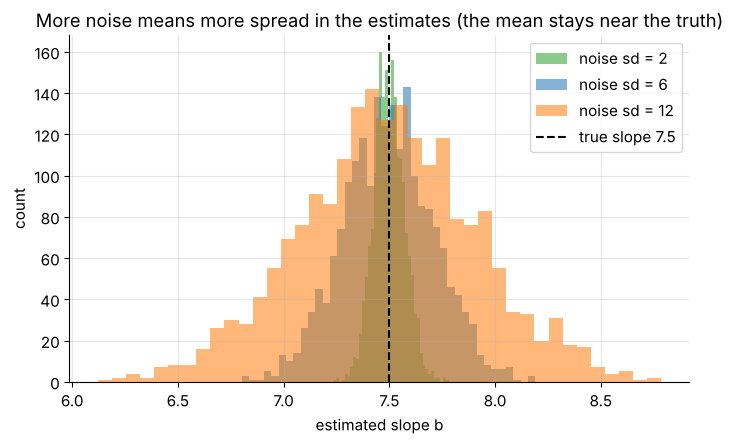

In [8]:
def simulate_slopes(sigma, n_sims=2000):
    slopes = np.empty(n_sims)
    for i in range(n_sims):
        y = linear(weeks, 20.0, 7.5) + rng.normal(0, sigma, weeks.size)
        slopes[i] = stats.linregress(weeks, y).slope
    return slopes

fig, ax = plt.subplots()
for sigma_i, colour in zip([2, 6, 12], ["tab:green", "tab:blue", "tab:orange"]):
    s = simulate_slopes(sigma_i)
    print(f"noise sd = {sigma_i:>2}: mean slope = {s.mean():.3f}, sd of slope = {s.std(ddof=1):.3f}")
    ax.hist(s, bins=40, alpha=0.55, color=colour, label=f"noise sd = {sigma_i}")
ax.axvline(7.5, color="k", ls="--", label="true slope 7.5")
ax.set_xlabel("estimated slope b")
ax.set_ylabel("count")
ax.set_title("More noise means more spread in the estimates (the mean stays near the truth)")
ax.legend()
plt.show()

## 6. Using your own data

Replace the simulated arrays with your measurements. Uncomment and adapt:

In [9]:
# import pandas as pd
# df = pd.read_csv("my_data.csv")                 # columns: t, y
# fit_own = stats.linregress(df["t"], df["y"])
# print(fit_own.intercept, fit_own.slope, fit_own.rvalue ** 2)

## 7. Exercises

1. Change `true_b` to 2 and the noise `sigma` to 15. Does the fitted slope still look reliable? What happens to $R^2$?
2. In section 2, use `y_int = linear(t_int, 5, 3)` and compute the ratios $y_{t+1}/y_t$. Are they constant? How does this differ from the exponential case?
3. Extrapolate the savings fit to week 200. Is a linear model realistic that far out? Which assumptions fail?
4. Simulate only 5 weeks of data instead of 21 and repeat section 5. How does the spread of the slope change?